# **XOR: WHY NONLINEARITY IS NECESSARY**

MLP:

## **Notation and Dimensions**

Let $m$ be the number of samples in the batch (training), and $n_h = 4$ the number of hidden neurons


| Symbol | Meaning | Dimension |
|------|------|---|
| $X$ | entries | $(m, 2)$ |
| $Y$ | labels in $\{0,1\}$ | $(m, 1)$ |
| $W_1$ | Hidden layer weights (column $j$ = normal vector of the $j$th rectangle) | $(2, 4)$ |
| $b_1$ | hidden bias (broadcasted across rows) | $(1, 4)$ |
| $Z_1 = XW_1 + b_1$ | hidden pre-activation | $(m, 4)$ |
| $A_1 = \mathrm{ReLU}(Z_1)$ | hidden activation | $(m, 4)$ |
| $W_2$ | output weights | $(4, 1)$ |
| $b_2$ | output bias | $(1, 1)$ |
| $Z_2 = A_1W_2 + b_2$ | logit | $(m, 1)$ |
| $\hat Y = \sigma(Z_2)$ | probability of class 1 | $(m, 1)$ |

## **1. Import and global configurations**

In [ ]:
# ---------------------------------------------------------------
# Imports and global configurations
# ---------------------------------------------------------------
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

SEED = 67
INIT_SEED = 0        # semente da INICIALIZAÇÃO dos pesos.
LAMBDA = 0.005       # coeficient L1
np.set_printoptions(precision=5, suppress=True)
plt.rcParams["figure.dpi"] = 110
print("SEED (data/split) =", SEED, "| INIT_SEED (weight) =", INIT_SEED, "| LAMBDA =", LAMBDA)

SEED (data/split) = 67 | INIT_SEED (weight) = 0 | LAMBDA = 0.005


## **2. Dataset XOR and split train/test**

4 gaussian clusters gaussianos isotropic with sd $\sigma = 0{,}35$ (moderated noise), 100 points by cluster → 400 points, 200 per class.
Class 0: $(-1,-1)$ and $(1,1)$. Class 1: $(-1,1)$ e $(1,-1)$.
A divisão é **75% train / 25% test**, made **only once** and reused.

X_train (300, 2) | X_test (100, 2)
class 1 in train: 0.507 | in test: 0.480


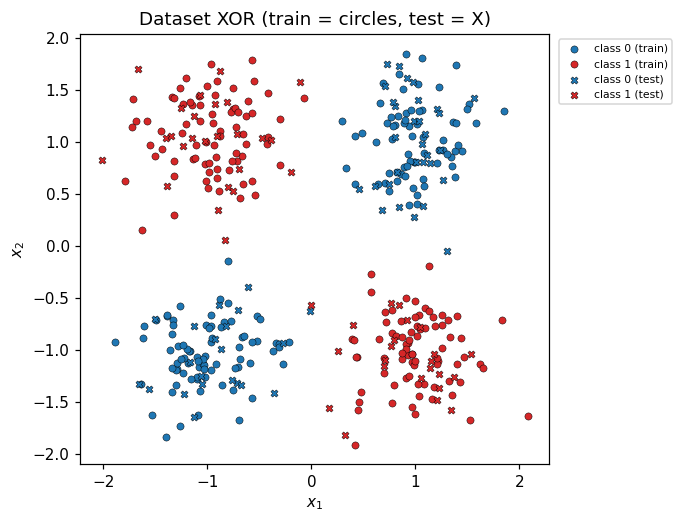

In [ ]:
# ---------------------------------------------------------------
# Generation of dataset (4 gaussians with XOR labels)
# ---------------------------------------------------------------
CENTERS = np.array([[-1., -1.], [1., 1.], [-1., 1.], [1., -1.]])
CLUSTER_LABELS = np.array([0, 0, 1, 1])      # (-1,-1),(1,1) -> 0 ; (-1,1),(1,-1) -> 1

def make_xor(n_per_cluster, sigma, rng):
    Xs, ys = [], []
    for c, lab in zip(CENTERS, CLUSTER_LABELS):
        Xs.append(c + sigma * rng.standard_normal((n_per_cluster, 2)))   # center + gaussina noise
        ys.append(np.full(n_per_cluster, lab))
    X = np.vstack(Xs)                                   # (4*n, 2)
    y = np.concatenate(ys).reshape(-1, 1).astype(float) # (4*n, 1)
    return X, y

rng = np.random.default_rng(SEED)
X_all, y_all = make_xor(n_per_cluster=100, sigma=0.35, rng=rng)

# Split train/test mixed (the same for logistic regression and MLP)
perm = rng.permutation(len(X_all))
n_train = int(0.75 * len(X_all))
idx_tr, idx_te = perm[:n_train], perm[n_train:]
X_train, y_train = X_all[idx_tr], y_all[idx_tr]
X_test,  y_test  = X_all[idx_te], y_all[idx_te]

print("X_train", X_train.shape, "| X_test", X_test.shape)
print("class 1 in train: %.3f | in test: %.3f" % (y_train.mean(), y_test.mean()))

def scatter_data(ax, title=""):
    for X, y, mk, nm in [(X_train, y_train, "o", "train"), (X_test, y_test, "X", "test")]:
        ax.scatter(X[y[:, 0] == 0, 0], X[y[:, 0] == 0, 1], c="tab:blue", marker=mk, s=22, edgecolor="k", linewidth=0.3, label=f"class 0 ({nm})")
        ax.scatter(X[y[:, 0] == 1, 0], X[y[:, 0] == 1, 1], c="tab:red",  marker=mk, s=22, edgecolor="k", linewidth=0.3, label=f"class 1 ({nm})")
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_title(title); ax.set_aspect("equal")

fig, ax = plt.subplots(figsize=(5.5, 5.5))
scatter_data(ax, "Dataset XOR (train = circles, test = X)")
ax.legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1)); plt.show()

## 3. **Geometry: why a single linear boundary doesn't separate XOR**

In [ ]:
# ---------------------------------------------------------------
# Numerical verification: Best possible stretch (exhaustive search)
# ---------------------------------------------------------------
# Mean of classes: Both within origin.
print("mean class 0:", X_train[y_train[:, 0] == 0].mean(0), "| mean class 1:", X_train[y_train[:, 0] == 1].mean(0))

angles = np.linspace(0, np.pi, 361)                 # direction of the normal vector w = (cos t, sin t)
offsets = np.linspace(-3, 3, 241)                   # displacement b of the line
best = (0.0, None, None)
for t in angles:
    w = np.array([np.cos(t), np.sin(t)])
    proj = X_train @ w                              # (m,) projection of each point in normal
    pred = (proj[:, None] > offsets[None, :])       # (m, n_offsets) prevision "class 1" to each b
    acc = (pred == (y_train > 0.5)).mean(axis=0)    # accuracy for each offset
    acc = np.maximum(acc, 1 - acc)                  # allow invert the signal
    k = acc.argmax()
    if acc[k] > best[0]:
        best = (acc[k], t, offsets[k])
print("Best accuracy reachable in TRAIN by any straight line (grade): %.3f" % best[0])

mean class 0: [-0.07669 -0.07495] | mean class 1: [0.03343 0.01392]
Best accuracy reachable in TRAIN by any straight line (grade): 0.757


### **3.1. A solution using 2 ReLU neurons**

In [ ]:
# ---------------------------------------------------------------
# Solution using 2 ReLU neurons
# ---------------------------------------------------------------
def hand_made(X):
    s = X[:, [0]] + X[:, [1]]                 # x1 + x2   (m,1)
    h = np.maximum(0, s) + np.maximum(0, -s)  # ReLU(s)+ReLU(-s) = |x1+x2|
    z2 = 3.0 - 3.0 * h                        # logit afim in h
    return 1 / (1 + np.exp(-z2))

for nome, X, y in [("train", X_train, y_train), ("test", X_test, y_test)]:
    print(f"accuracy ({nome}): {((hand_made(X) > 0.5) == (y > 0.5)).mean():.3f}")

accuracy (train): 0.960
accuracy (test): 0.950


## **4. Complete Derivation (Forward → Backward) with Dimensions**

### 4.1 Forward
$$Z_1=XW_1+b_1\ (m,4),\quad A_1=\mathrm{ReLU}(Z_1)\ (m,4),\quad Z_2=A_1W_2+b_2\ (m,1),\quad \hat Y=\sigma(Z_2)\ (m,1).$$

### 4.2 Output gradient: $\partial\mathcal L_{BCE}/\partial Z_2$
For a sample, $\ell_i=-y_i\log\hat y_i-(1-y_i)\log(1-\hat y_i)$ with $\hat y_i=\sigma(z_{2,i})$:
$$\frac{\partial \ell_i}{\partial \hat y_i}=-\frac{y_i}{\hat y_i}+\frac{1-y_i}{1-\hat y_i}=\frac{\hat y_i-y_i}{\hat y_i(1-\hat y_i)},\qquad
\frac{\partial\hat y_i}{\partial z_{2,i}}=\sigma'(z_{2,i})=\hat y_i(1-\hat y_i).$$
Multiplying (chain rule), the factor $\hat y_i(1-\hat y_i)$ cancels out:
$\ \partial \ell_i/\partial z_{2,i}=\hat y_i-y_i$. Since $\mathcal L_{BCE}=\frac1m\sum_i\ell_i$:
$$\boxed{dZ_2=\frac{1}{m}(\hat Y-Y)}\qquad (m,1).$$

### 4.3 Output Layer
In indices, $z_{2,i}=\sum_k a_{ik}\,w_{2,k}+b_2$. Then
$$\frac{\partial\mathcal L}{\partial w_{2,k}}=\sum_i \frac{\partial\mathcal L}{\partial z_{2,i}}\,a_{ik}
\ \Rightarrow\ \boxed{dW_2=A_1^\top dZ_2}\ \ (4,m)(m,1)=(4,1),$$
$$\frac{\partial\mathcal L}{\partial b_2}=\sum_i\frac{\partial\mathcal L}{\partial z_{2,i}}\ \Rightarrow\ \boxed{db_2=\sum_{\text{lines}} dZ_2}\ \ (1,1),$$
$$\frac{\partial\mathcal L_{BCE}}{\partial a_{ik}}=\frac{\partial\mathcal L}{\partial z_{2,i}}\,w_{2,k}\ \Rightarrow\ \boxed{dA_{1,BCE}=dZ_2\,W_2^\top}\ \ (m,1)(1,4)=(m,4). $$
The transpose of $A_1$ appears because each weight $w_{2,k}$ is summed over the $m$ samples (contraction in index $i$); the sum over $db_2$ exists because the same bias is shared by all samples.

### 4.4 L1 Term in the Activation (R1)
$$R=\frac{\lambda}{m}\sum_{i,j}|a_{ij}|\ \Rightarrow\ \frac{\partial R}{\partial a_{ij}}=\frac{\lambda}{m}\,\mathrm{sign}(a_{ij}),$$
where $\mathrm{sign}(0)=0$ is the **chosen subgradient** (at $a=0$, the subdifferential of $|a|$ is the interval $[-1,1]$; we choose the element $0$).
The matrix $A_1$ appears in **two** paths of the graph: (i) toward the output (BCE) and (ii) directly in $R$. By the multivariate chain rule, the gradients **add up** *before* passing through the ReLU:
$$\boxed{dA_{1,total}=dA_{1,BCE}+\frac{\lambda}{m}\,\mathrm{sign}(A_1)}\qquad (m,4).$$

### 4.5 Through the ReLU
$a_{ij}=\max(0,z_{1,ij})$ has a derivative of $\mathbb 1[z_{1,ij}>0]$ (we use $\mathrm{ReLU}'(0)=0$). **Point-wise** product (each entry of $A_1$ depends only on the corresponding entry of $Z_1$):
$$\boxed{dZ_1=dA_{1,total}\odot\mathbb 1[Z_1>0]}\qquad (m,4).$$

### 4.6 First Layer
$z_{1,ij}=\sum_p x_{ip}w_{1,pj}+b_{1,j}$ ⇒
$$\boxed{dW_1 = X^\top dZ_1} \ \ (2,m)(m,4) = (2,4),\qquad \boxed{db_1 = \sum_{\text{rows}} dZ_1} \ \ (1,4).$$

### 4.7 Important observations regarding the L1 term
* Since $A_1\ge 0$, $|a|=a$ and $R=\frac{\lambda}{m}\sum a_{ij}$ (linear sum). Furthermore, $a_{ij}>0\iff z_{1,ij}>0$. Therefore, where the ReLU is inactive, $\mathrm{sign}(a)=0$ **and** the mask is $0$; where it is active, $\mathrm{sign}(a)=1$. The L1 term effectively adds $+\lambda/m$ to $dZ_1$ **only at the active inputs**, pushing $z_{1,ij}$ downward with a **constant** force (not proportional to the value, unlike L2).
* The convention $\mathrm{sign}(0)=0$ does not alter the gradient, since the ReLU mask at $z=0$ is already $0$.
* **ReLU already produces exact zeros** (where $z\le0$). L1 calls for *more* zeros / smaller activations: it favors fewer samples activating each neuron and, when they do activate, a small magnitude.

## **5. Implementation in NumPy (forward, losses, backward)**
The variable names follow the derivation notation exactly: `Z1, A1, Z2, Yhat, dZ2, dW2, db2, dA1, dZ1, dW1, db1`.

In [ ]:
# ---------------------------------------------------------------
# Basic Functions
# ---------------------------------------------------------------
def relu(Z):
    return np.maximum(0.0, Z)

def sigmoid(Z):
    # Stable form: sigma(z) = 0.5 * (1 + tanh(z/2)) prevents exp overflow
    return 0.5 * (1.0 + np.tanh(0.5 * Z))

def bce_from_logits(Z2, Y):
    #  Mean BCE expressed in terms of the logit (stable): max(z,0) - z*y + log(1+exp(-|z|))
    return np.mean(np.maximum(Z2, 0.0) - Z2 * Y + np.log1p(np.exp(-np.abs(Z2))))

def accuracy(Yhat, Y):
    return np.mean((Yhat > 0.5) == (Y > 0.5))

# ---------------------------------------------------------------
# Gaussian initialization (scales w1, w2)
# ---------------------------------------------------------------
def init_params(seed, n_in=2, n_h=4, w1_scale=1.0, w2_scale=1.0):
    r = np.random.default_rng(seed)
    return {
        "W1": r.standard_normal((n_in, n_h)) * w1_scale,   # (2,4)  columns = normals of the hidden lines
        "b1": np.zeros((1, n_h)),                          # (1,4)
        "W2": r.standard_normal((n_h, 1)) * w2_scale,      # (4,1)
        "b2": np.zeros((1, 1)),                            # (1,1)
    }

def copy_params(P):
    return {k: v.copy() for k, v in P.items()}

# ---------------------------------------------------------------
# Forward:  Z1 = X W1 + b1 ; A1 = ReLU(Z1) ; Z2 = A1 W2 + b2 ; Yhat = sigmoid(Z2)
# ---------------------------------------------------------------
def forward(X, P):
    Z1 = X @ P["W1"] + P["b1"]        # (m,2)@(2,4) + (1,4) -> (m,4)
    A1 = relu(Z1)                     # (m,4)
    Z2 = A1 @ P["W2"] + P["b2"]       # (m,4)@(4,1) + (1,1) -> (m,1)
    Yhat = sigmoid(Z2)                # (m,1)
    return Yhat, {"X": X, "Z1": Z1, "A1": A1, "Z2": Z2}

# ---------------------------------------------------------------
# Objective:  L_total = L_BCE + R ,   R = (lam/m) * ||A1||_1
# ---------------------------------------------------------------
def objective(X, Y, P, lam):
    _, c = forward(X, P)
    m = X.shape[0]
    L_bce = bce_from_logits(c["Z2"], Y)
    R = (lam / m) * np.sum(np.abs(c["A1"]))
    return L_bce + R, L_bce, R

# ---------------------------------------------------------------
# Backward
# ---------------------------------------------------------------
def backward(cache, Y, P, lam):
    X, Z1, A1 = cache["X"], cache["Z1"], cache["A1"]
    Yhat = sigmoid(cache["Z2"])
    m = X.shape[0]

    dZ2 = (Yhat - Y) / m                          # (m,1)   sigmoid + BCE  (3.2)
    dW2 = A1.T @ dZ2                              # (4,1)   sum over samples (3.3)
    db2 = np.sum(dZ2, axis=0, keepdims=True)      # (1,1)
    dA1_bce = dZ2 @ P["W2"].T                     # (m,4)

    dA1 = dA1_bce + (lam / m) * np.sign(A1)       # (m,4)   subgradient L1, sign(0)=0 (3.4)
    dZ1 = dA1 * (Z1 > 0)                          # (m,4)   máscara da ReLU, element-wise product(3.5)
    dW1 = X.T @ dZ1                               # (2,4)   (3.6)
    db1 = np.sum(dZ1, axis=0, keepdims=True)      # (1,4)
    return {"W1": dW1, "b1": db1, "W2": dW2, "b2": db2}

## **6. Gradient check (central finite differences) of the TOTAL objective function**


$$\frac{\partial \mathcal L_{total}}{\partial\theta}\approx\frac{\mathcal L_{total}(\theta+\varepsilon)-\mathcal L_{total}(\theta-\varepsilon)}{2\varepsilon},\qquad \varepsilon=10^{-6}.$$

In [ ]:
# ---------------------------------------------------------------
# Gradient check
# ---------------------------------------------------------------
def numerical_grad(f, P, key, idx, eps=1e-6):
    old = P[key][idx]
    P[key][idx] = old + eps; fp = f(P)
    P[key][idx] = old - eps; fm = f(P)
    P[key][idx] = old
    return (fp - fm) / (2 * eps)

def rel_err(a, n):
    return abs(a - n) / max(abs(a) + abs(n), 1e-12)

def gradient_check(P, X, Y, lam, eps=1e-6, label=""):
    f = lambda Q: objective(X, Y, Q, lam)[0]
    _, cache = forward(X, P)
    g = backward(cache, Y, P, lam)

    # Select neuron j whose fraction of active samples is closest to 0.5 (interesting case)
    frac_active = (cache["Z1"] > 0).mean(axis=0)
    j = int(np.argmin(np.abs(frac_active - 0.5)))
    p = 0                                              # element W1[p, j]
    margin = np.min(np.abs(cache["Z1"][:, j]))         # Minimum distance from Z1[:,j] to the kink at z=0
    shift = eps * np.max(np.abs(X[:, p]))              # How much Z1[:,j] moves when W1[p,j] is perturbed
    ok_margin = margin > 10 * shift

    out = []
    for key, idx in [("W1", (p, j)), ("W2", (j, 0))]:
        a = g[key][idx]; n = numerical_grad(f, P, key, idx, eps)
        out.append((key, idx, a, n, rel_err(a, n)))

    print(f"--- {label} (lam={lam}) | neuron j={j}, fraction active={frac_active[j]:.2f}")
    print(f"    margem min|Z1[:,j]| = {margin:.2e} vs slope {shift:.1e} -> sem cruzar kink: {ok_margin}")
    for key, idx, a, n, e in out:
        print(f"    {key}{list(idx)}: analytic={a:+.10f} | numerical={n:+.10f} | relactive error={e:.2e}")
    return all(o[4] < 1e-6 for o in out) and ok_margin

P_init = init_params(INIT_SEED)       # FIXED initialization, reused in all comparisons
print("Gradient check in initial point:")
r1 = gradient_check(P_init, X_train, y_train, LAMBDA, label="inicialization")
r2 = gradient_check(P_init, X_train, y_train, 5.0,    label="inicialization, L1 strong")
print("Completed:", r1, r2)

Gradient check in initial point:
--- inicialization (lam=0.005) | neuron j=1, fraction active=0.48
    margem min|Z1[:,j]| = 1.16e-02 vs slope 2.1e-06 -> sem cruzar kink: True
    W1[0, 1]: analytic=-0.2782940041 | numerical=-0.2782940041 | relactive error=1.07e-10
    W2[1, 0]: analytic=-0.0887322012 | numerical=-0.0887322012 | relactive error=9.31e-11
--- inicialization, L1 strong (lam=5.0) | neuron j=1, fraction active=0.48
    margem min|Z1[:,j]| = 1.16e-02 vs slope 2.1e-06 -> sem cruzar kink: True
    W1[0, 1]: analytic=-0.3571044863 | numerical=-0.3571044864 | relactive error=1.53e-10
    W2[1, 0]: analytic=-0.0887322012 | numerical=-0.0887322011 | relactive error=4.06e-10
Completed: True True


## **7. Baseline: logistic regression (same training/test split)**

$$z=Xw+b,\quad \hat y=\sigma(z),\quad dz=\tfrac1m(\hat y-y),\quad dw=X^\top dz,\quad db=\textstyle\sum dz .$$
This is the special case of an MLP without a hidden layer: the boundary is $w^\top x+b=0$ (a straight line).

In [ ]:
# ---------------------------------------------------------------
# Logistic regression in NumPy (batch gradient descent)
# ---------------------------------------------------------------
def train_logreg(Xtr, Ytr, Xte, Yte, lr=0.5, epochs=3000):
    w = np.zeros((2, 1)); b = np.zeros((1, 1))         # convex problem: zeros are fine
    hist = {"loss_tr": [], "loss_te": [], "acc_tr": [], "acc_te": []}
    m = Xtr.shape[0]
    for ep in range(epochs):
        z = Xtr @ w + b
        yhat = sigmoid(z)
        hist["loss_tr"].append(bce_from_logits(z, Ytr)); hist["acc_tr"].append(accuracy(yhat, Ytr))
        zt = Xte @ w + b
        hist["loss_te"].append(bce_from_logits(zt, Yte)); hist["acc_te"].append(accuracy(sigmoid(zt), Yte))
        dz = (yhat - Ytr) / m                           # (m,1)
        w -= lr * (Xtr.T @ dz)                          # (2,1)
        b -= lr * dz.sum(axis=0, keepdims=True)         # (1,1)
    return w, b, hist

w_lr, b_lr, hist_lr = train_logreg(X_train, y_train, X_test, y_test)
print("w =", w_lr.ravel(), "| b =", b_lr.ravel())
print(f"LogReg  train: BCE={hist_lr['loss_tr'][-1]:.4f} acc={hist_lr['acc_tr'][-1]:.3f} | "
      f"test: BCE={hist_lr['loss_te'][-1]:.4f} acc={hist_lr['acc_te'][-1]:.3f}")

w = [0.09997 0.07587] | b = [0.03114]
LogReg  train: BCE=0.6908 acc=0.657 | test: BCE=0.7067 acc=0.540


## **8. MLP Training: $\lambda=0$ vs $\lambda=0{,}005$**

Same data, **same initialization** (`P_init`), same optimizer (batch gradient descent, fixed step size), and same number of epochs. The only difference is the value of $\lambda$. The log records the following for each epoch: **unregularized** BCE, $R$ term, total objective, accuracy, fraction of zeros in $A_1$, and $\overline{|A_1|}$.

In [ ]:
# ---------------------------------------------------------------
# MLP Training (Batch Gradient Descent)
# ---------------------------------------------------------------
LR, EPOCHS = 0.5, 5000

def hidden_stats(A1):
    return (A1 == 0).mean(), np.abs(A1).mean()     # proportion of zeros, mean |A1|

def train_mlp(P0, lam, Xtr, Ytr, Xte, Yte, lr=LR, epochs=EPOCHS):
    P = copy_params(P0)                            # copy: P0 is never modified
    keys = ["loss_bce_tr", "R_tr", "loss_total_tr", "acc_tr", "loss_bce_te", "acc_te", "frac_zero_tr", "mean_abs_tr"]
    H = {k: [] for k in keys}
    for ep in range(epochs):
        Yhat, cache = forward(Xtr, P)
        Ltot, Lbce, R = objective(Xtr, Ytr, P, lam)
        fz, ma = hidden_stats(cache["A1"])
        Yhat_te, cache_te = forward(Xte, P)
        for k, v in zip(keys, [Lbce, R, Ltot, accuracy(Yhat, Ytr), bce_from_logits(cache_te["Z2"], Yte),
                               accuracy(Yhat_te, Yte), fz, ma]):
            H[k].append(v)
        g = backward(cache, Ytr, P, lam)
        for k in P:                                # gradient step: theta <- theta - lr * dtheta
            P[k] -= lr * g[k]
    return P, H

P_l0, H_l0 = train_mlp(P_init, 0.0,    X_train, y_train, X_test, y_test)
P_l1, H_l1 = train_mlp(P_init, LAMBDA, X_train, y_train, X_test, y_test)
print("Train succeded | Loss total initial/final (lam=0):     %.4f -> %.4f" % (H_l0["loss_total_tr"][0], H_l0["loss_total_tr"][-1]))
print("                 | Loss total initial/final (lam=0.005): %.4f -> %.4f" % (H_l1["loss_total_tr"][0], H_l1["loss_total_tr"][-1]))

# Diagnosis: INIT_SEED=67 confines the training to a small area (≈ 3 of the 4 correct clusters)
P_bad, H_bad = train_mlp(init_params(67), 0.0, X_train, y_train, X_test, y_test)
print("Diagnostic (INIT_SEED=67, λ=0): acc train=%.3f | acc test=%.3f | BCE train=%.4f -> local minimum" %
      (H_bad["acc_tr"][-1], H_bad["acc_te"][-1], H_bad["loss_bce_tr"][-1]))

# Gradient check also at the TRAINED point (with λ = 0.005), checking the margin of the kink
_ = gradient_check(P_l1, X_train, y_train, LAMBDA, label="trained model")

treino concluído | perda total inicial/final (lam=0):     0.7958 -> 0.0011
                 | perda total inicial/final (lam=0.005): 0.8038 -> 0.0195
Diagnóstico (INIT_SEED=67, λ=0): acc treino=0.743 | acc teste=0.770 | BCE treino=0.3608 -> mínimo local
--- modelo treinado (lam=0.005) | neuron j=0, fraction active=0.51
    margem min|Z1[:,j]| = 2.03e-02 vs slope 2.1e-06 -> sem cruzar kink: True
    W1[0, 0]: analytic=-0.0002090896 | numerical=-0.0002090896 | relactive error=6.90e-10
    W2[0, 0]: analytic=+0.0008345272 | numerical=+0.0008345272 | relactive error=1.03e-09


## **9. Final Metrics (R2, R3)**
We report the following separately: **unregularized** BCE and accuracy (predictive metric), the $R$ term, the total regularized training objective, the **fraction of hidden activations that are exactly zero**, and the **mean of $|A_1|$**.

In [ ]:
# ---------------------------------------------------------------
# Results Table
# ---------------------------------------------------------------
def summarize(name, P, lam, with_hidden=True):
    row = {"model": name}
    for nome, X, Y in [("train", X_train, y_train), ("test", X_test, y_test)]:
        Yhat, c = forward(X, P)
        row[f"BCE {nome}"] = bce_from_logits(c["Z2"], Y)       # WITHOUT regularization
        row[f"acc {nome}"] = accuracy(Yhat, Y)
        if nome == "train":
            row["R (train)"] = (lam / X.shape[0]) * np.abs(c["A1"]).sum()
            row["L_total (train)"] = row["BCE train"] + row["R (train)"]
        fz, ma = hidden_stats(c["A1"])
        row[f"frac A1=0 {nome}"] = fz
        row[f"mean |A1| {nome}"] = ma
    return row

row_lr = {"model": "Logistic Regression",
          "BCE train": hist_lr["loss_tr"][-1], "acc train": hist_lr["acc_tr"][-1],
          "BCE test": hist_lr["loss_te"][-1], "acc test": hist_lr["acc_te"][-1]}
df = pd.DataFrame([row_lr, summarize("MLP λ=0", P_l0, 0.0), summarize("MLP λ=0.005", P_l1, LAMBDA)]).set_index("model")
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 20)
display(df.round(4))

# Activity per neuron (training): the fraction of samples in which each neuron is active
for nome, P in [("λ=0", P_l0), ("λ=0.005", P_l1)]:
    _, c = forward(X_train, P)
    print(f"Fraction of active samples by neuron ({nome}):", (c["Z1"] > 0).mean(0))

,BCE train,acc train,BCE test,acc test,R (train),L_total (train),frac A1=0 train,mean |A1| train,frac A1=0 test,mean |A1| test
model,,,,,,,,,,
Logistic Regression,0.6908,0.6567,0.7067,0.54,NaN,NaN,NaN,NaN,NaN,NaN
MLP λ=0,0.0011,1.0000,0.0332,0.98,0.0000,0.0011,0.5375,1.6606,0.5250,1.6711
MLP λ=0.005,0.0043,1.0000,0.0565,0.98,0.0152,0.0195,0.6200,0.7594,0.5925,0.7671


Fraction of active samples by neuron (λ=0): [0.52    0.47333 0.47    0.38667]
Fraction of active samples by neuron (λ=0.005): [0.51 0.3  0.41 0.3 ]


### **9.1 $\lambda$ Sweep**

The specified $\lambda=0{,}005$ is small when divided by $m$. This scan, using the **same initialization and the same data**, shows what happens when L1 really “bites”—and tests the warning that greater sparsity **does not** imply better classification.

In [ ]:
# ---------------------------------------------------------------
# Lambda sweep (Only exploratory; The requirement is λ=0 vs λ=0.005)
# ---------------------------------------------------------------
rows = []
for lam in [0.0, 0.005, 0.05, 0.5, 2.0, 5.0]:
    P_s, _ = train_mlp(P_init, lam, X_train, y_train, X_test, y_test)
    r = summarize(f"λ={lam}", P_s, lam)
    rows.append({k: r[k] for k in ["model", "BCE test", "acc test", "L_total (train)", "frac A1=0 train", "mean |A1| train"]})
display(pd.DataFrame(rows).set_index("model").round(4))

,BCE test,acc test,L_total (train),frac A1=0 train,mean |A1| train
model,,,,,
λ=0.0,0.0332,0.98,0.0011,0.5375,1.6606
λ=0.005,0.0565,0.98,0.0195,0.6200,0.7594
λ=0.05,0.0813,0.97,0.0695,0.7200,0.2308
λ=0.5,0.5202,0.72,0.5810,0.9458,0.0150
λ=2.0,0.6938,0.48,0.6931,1.0000,0.0000
λ=5.0,0.6938,0.48,0.6931,1.0000,0.0000


## **10. Graphs**

### 10.1 Loss curves

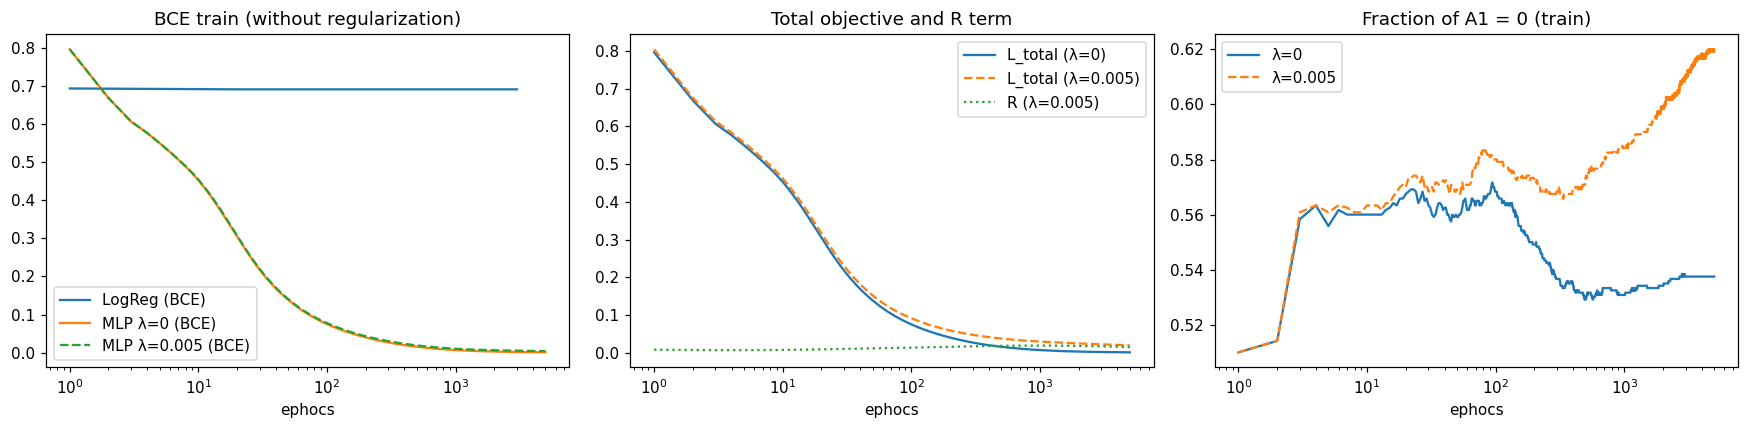

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4))
ep = np.arange(1, EPOCHS + 1)
axs[0].plot(np.arange(1, len(hist_lr["loss_tr"]) + 1), hist_lr["loss_tr"], label="LogReg (BCE)")
axs[0].plot(ep, H_l0["loss_bce_tr"], label="MLP λ=0 (BCE)")
axs[0].plot(ep, H_l1["loss_bce_tr"], "--", label="MLP λ=0.005 (BCE)")
axs[0].set_title("BCE train (without regularization)"); axs[0].set_xscale("log"); axs[0].legend(); axs[0].set_xlabel("ephocs")

axs[1].plot(ep, H_l0["loss_total_tr"], label="L_total (λ=0)")
axs[1].plot(ep, H_l1["loss_total_tr"], "--", label="L_total (λ=0.005)")
axs[1].plot(ep, H_l1["R_tr"], ":", label="R (λ=0.005)")
axs[1].set_title("Total objective and R term"); axs[1].set_xscale("log"); axs[1].legend(); axs[1].set_xlabel("ephocs")

axs[2].plot(ep, H_l0["frac_zero_tr"], label="λ=0"); axs[2].plot(ep, H_l1["frac_zero_tr"], "--", label="λ=0.005")
axs[2].set_title("Fraction of A1 = 0 (train)"); axs[2].set_xscale("log"); axs[2].legend(); axs[2].set_xlabel("ephocs")
plt.tight_layout(); plt.show()

### 10.2 Probability Maps and Decision Boundaries (Logistic Regression vs. MLP)
The black curve represents the level $\hat y=0{,}5$. On the left, the decision boundary for logistic regression is **a straight line**; on the right, that of the MLP is **piecewise linear**.

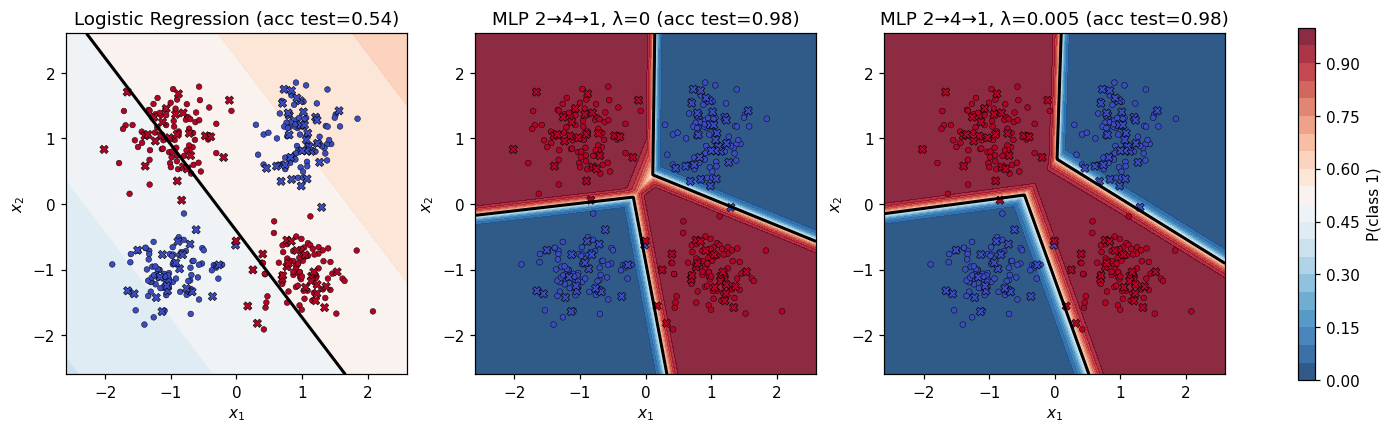

In [ ]:
# ---------------------------------------------------------------
# 2-D grid for probability maps
# ---------------------------------------------------------------
gx = np.linspace(-2.6, 2.6, 400)
GX, GY = np.meshgrid(gx, gx)
GRID = np.c_[GX.ravel(), GY.ravel()]                 # (160000, 2)

def prob_map(ax, probs, title):
    cs = ax.contourf(GX, GY, probs.reshape(GX.shape), levels=np.linspace(0, 1, 21), cmap="RdBu_r", alpha=0.85)
    ax.contour(GX, GY, probs.reshape(GX.shape), levels=[0.5], colors="k", linewidths=2)
    ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train[:, 0], cmap="coolwarm", edgecolor="k", s=14, linewidth=0.3)
    ax.scatter(X_test[:, 0], X_test[:, 1], c=y_test[:, 0], cmap="coolwarm", edgecolor="k", s=30, marker="X", linewidth=0.4)
    ax.set_title(title); ax.set_aspect("equal"); ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
    return cs

p_lr = sigmoid(GRID @ w_lr + b_lr)
p_l0 = forward(GRID, P_l0)[0]
p_l1 = forward(GRID, P_l1)[0]

fig, axs = plt.subplots(1, 3, figsize=(17, 5.2))
prob_map(axs[0], p_lr, f"Logistic Regression (acc test={hist_lr['acc_te'][-1]:.2f})")
prob_map(axs[1], p_l0, f"MLP 2→4→1, λ=0 (acc test={H_l0['acc_te'][-1]:.2f})")
cs = prob_map(axs[2], p_l1, f"MLP 2→4→1, λ=0.005 (acc test={H_l1['acc_te'][-1]:.2f})")
fig.colorbar(cs, ax=axs, shrink=0.8, label="P(class 1)"); plt.show()

### 10.3 Lines of the hidden neurons $Z_{1,j}=0$ and activations $A_{1,j}$
Each hidden neuron $j$ defines the line $w_{1,j}^\top x+b_{1,j}=0$ with normal vector $w_{1,j}$ (column $j$ of $W_1$). On the side where $z_{1,j}>0$, the activation grows linearly (ramp); on the other side, it is exactly $0$. The ReLU **folds** the plane along this line.

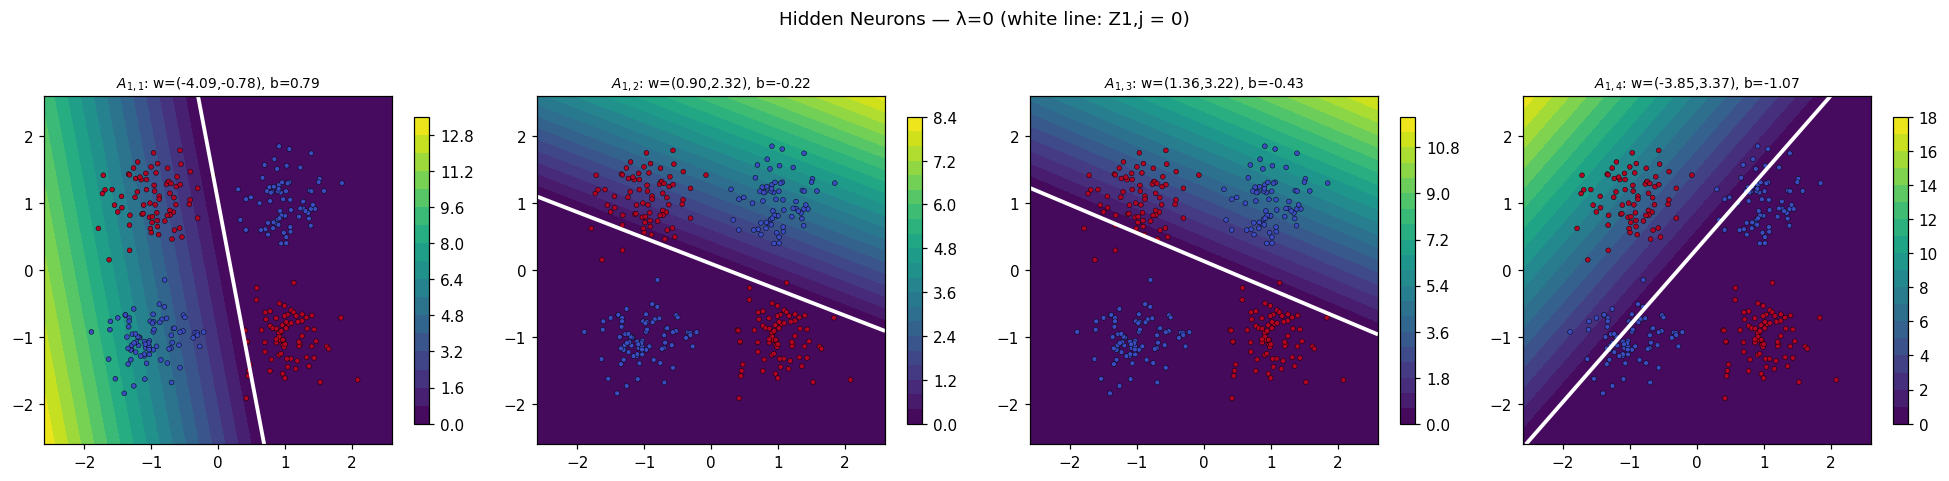

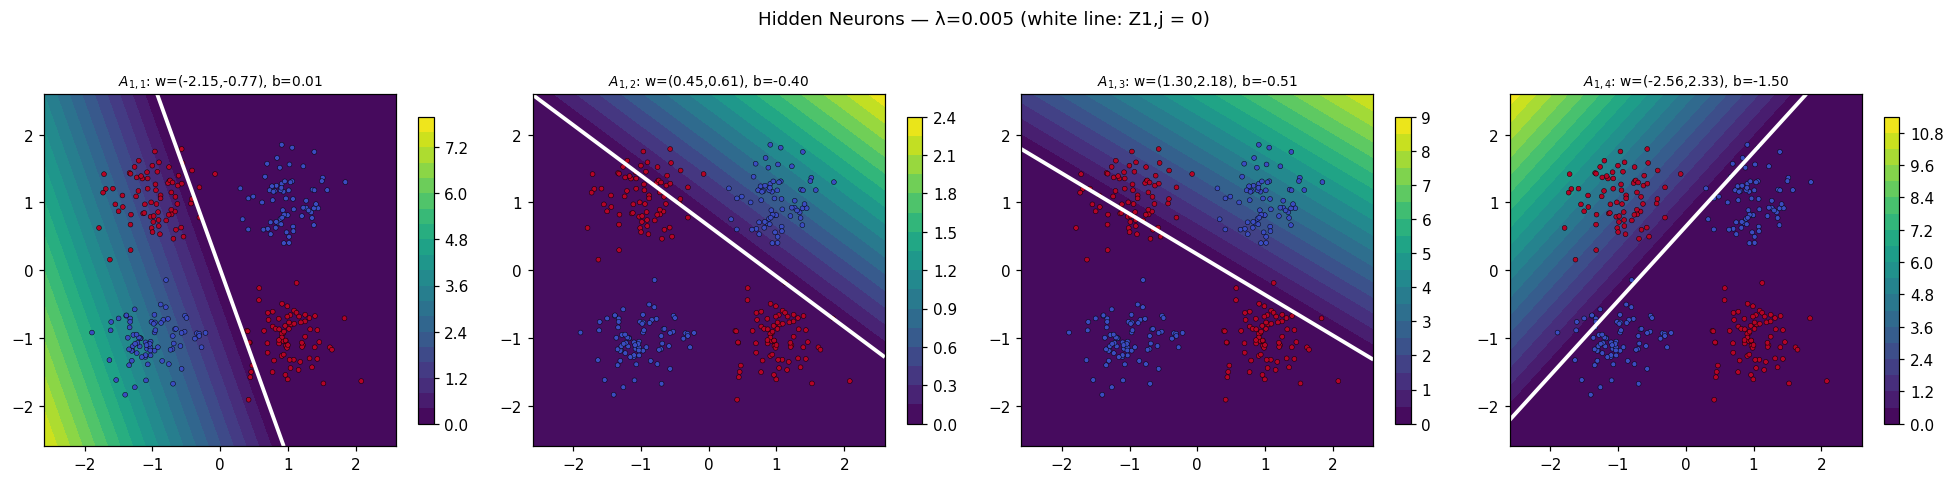

In [ ]:
def plot_hidden_units(P, title):
    _, c = forward(GRID, P)
    Z1g, A1g = c["Z1"], c["A1"]
    fig, axs = plt.subplots(1, 4, figsize=(18, 4.6))
    for j in range(4):
        ax = axs[j]
        im = ax.contourf(GX, GY, A1g[:, j].reshape(GX.shape), levels=20, cmap="viridis")
        ax.contour(GX, GY, Z1g[:, j].reshape(GX.shape), levels=[0], colors="w", linewidths=2.5)   # reta Z1,j = 0
        ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train[:, 0], cmap="coolwarm", edgecolor="k", s=10, linewidth=0.3)
        w = P["W1"][:, j]
        ax.set_title(f"$A_{{1,{j+1}}}$: w=({w[0]:.2f},{w[1]:.2f}), b={P['b1'][0, j]:.2f}", fontsize=9)
        ax.set_aspect("equal"); ax.set_xlim(gx[0], gx[-1]); ax.set_ylim(gx[0], gx[-1])
        fig.colorbar(im, ax=ax, shrink=0.7)
    fig.suptitle(title); plt.tight_layout(); plt.show()

plot_hidden_units(P_l0, "Hidden Neurons — λ=0 (white line: Z1,j = 0)")
plot_hidden_units(P_l1, "Hidden Neurons — λ=0.005 (white line: Z1,j = 0)")

### 9.4 Linear Regions in Parts and Final Boundary
The four lines $Z_{1,j}=0$ divide the plane into regions. In each region, the **activation pattern** $s\in\{0,1\}^4$ (which neurons are active) is constant, so
$$A_1 = Z_1\odot s \ \Rightarrow\ Z_2=\big(XW_1+b_1\big)\,\mathrm{diag}(s)\, W_2+b_2 = X\,\underbrace{W_1\mathrm{diag}(s)W_2}_{w_{\mathrm{eff}}(s)}+\underbrace{b_1\mathrm{diag}(s)W_2+b_2}_{b_{\mathrm{eff}}(s)},$$
that is, **within each region, the logit is linear**. The boundary $Z_2=0$ is therefore composed of line segments that change slope as they cross the hidden lines—exactly the class of boundaries that a single line cannot represent.

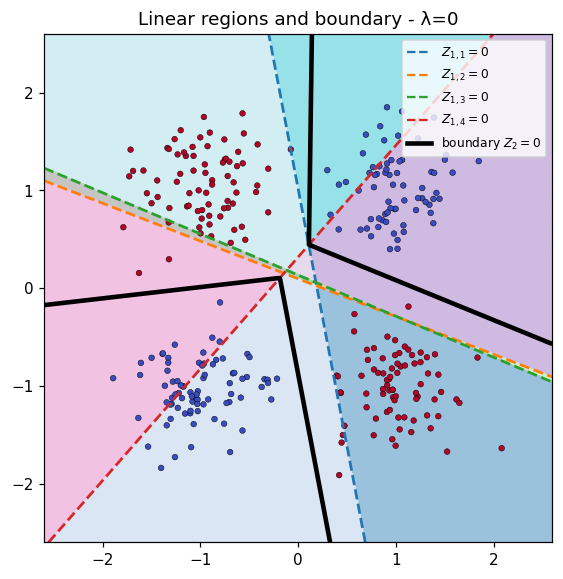

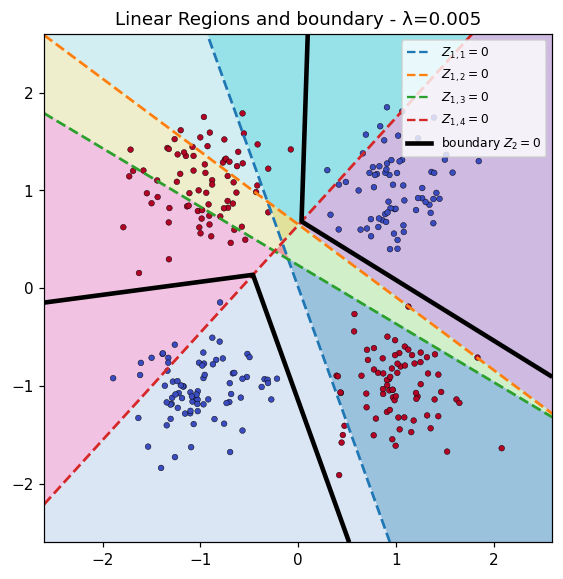

different ativations pattern in window -  λ=0: 11 | λ=0.005: 10
error maximum |Z2 - (x·w_eff + b_eff)| in 1000 points: [0.]


In [ ]:
def plot_regions(P, title):
    _, c = forward(GRID, P)
    pattern = ((c["Z1"] > 0) * (2 ** np.arange(4))).sum(axis=1)    #entire code to the activation pattern
    fig, ax = plt.subplots(figsize=(6.5, 6))
    ax.imshow(pattern.reshape(GX.shape), origin="lower", extent=[gx[0], gx[-1], gx[0], gx[-1]], cmap="tab20", alpha=0.45)
    for j in range(4):
        ax.contour(GX, GY, c["Z1"][:, j].reshape(GX.shape), levels=[0], colors=f"C{j}", linewidths=1.8, linestyles="--")
        ax.plot([], [], color=f"C{j}", ls="--", label=f"$Z_{{1,{j+1}}}=0$")
    ax.contour(GX, GY, c["Z2"].reshape(GX.shape), levels=[0], colors="k", linewidths=3)      # final boundary
    ax.plot([], [], color="k", lw=3, label="boundary $Z_2=0$")
    ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train[:, 0], cmap="coolwarm", edgecolor="k", s=14, linewidth=0.3)
    ax.set_title(title); ax.set_aspect("equal"); ax.legend(fontsize=8, loc="upper right")
    plt.show()
    return pattern

pat0 = plot_regions(P_l0, "Linear regions and boundary - λ=0")
pat1 = plot_regions(P_l1, "Linear Regions and boundary - λ=0.005")
print("different ativations pattern in window -  λ=0:", len(np.unique(pat0)), "| λ=0.005:", len(np.unique(pat1)))

#Verification: Within each region, the logit is EXACTLY affine, with (w_eff, b_eff) depending only on the standard s
def effective_affine(P, s):
    D = np.diag(s.astype(float))
    return P["W1"] @ D @ P["W2"], P["b1"] @ D @ P["W2"] + P["b2"]   # (2,1), (1,1)

r = np.random.default_rng(SEED + 1)
pts = r.uniform(-2.5, 2.5, size=(1000, 2))
_, cpts = forward(pts, P_l1)
err = 0.0
for i in range(len(pts)):
    s = (cpts["Z1"][i] > 0)
    w_eff, b_eff = effective_affine(P_l1, s)
    err = max(err, abs((pts[i] @ w_eff + b_eff)[0] - cpts["Z2"][i, 0]))
print("error maximum |Z2 - (x·w_eff + b_eff)| in 1000 points:", err)